# Import and read data

In [60]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
plt.style.use('ggplot')
pd.set_option('display.max_columns', 200)


In [61]:
from sklearn import datasets
from sklearn.decomposition import PCA

In [62]:
# Load the Iris dataset (sklearn instruction)
iris = datasets.load_iris()

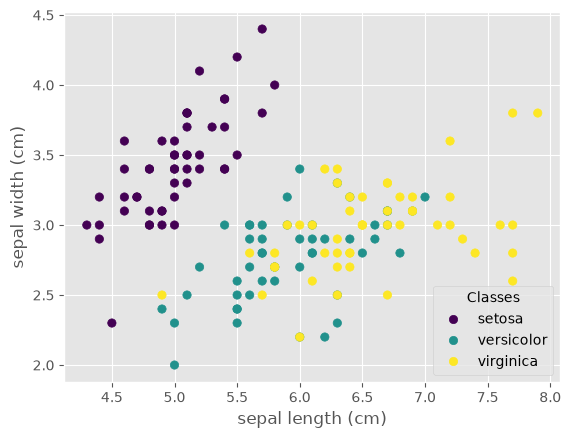

In [63]:
# Scatter plot of the dataset (sklearn instruction)
_, ax = plt.subplots()
scatter = ax.scatter(iris.data[:, 0], iris.data[:, 1], c=iris.target)
ax.set(xlabel=iris.feature_names[0], ylabel=iris.feature_names[1])
_ = ax.legend(
    scatter.legend_elements()[0], iris.target_names, loc="lower right", title="Classes"
)
plt.show()

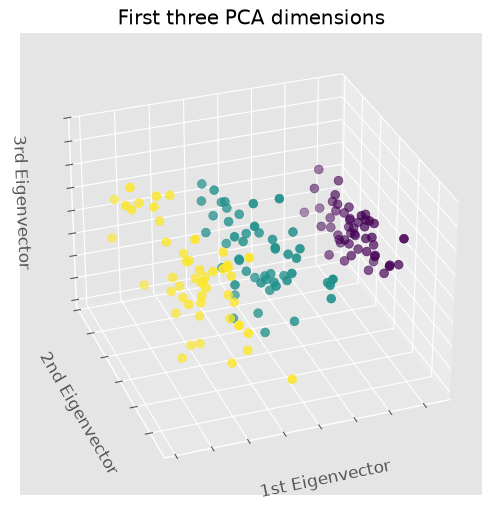

In [64]:
# Scatter plot of the dataset in 3D (sklearn instruction)
import mpl_toolkits.mplot3d  # noqa: F401


fig = plt.figure(1, figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d", elev=-150, azim=110)

X_reduced = PCA(n_components=3).fit_transform(iris.data)
ax.scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    X_reduced[:, 2],
    c=iris.target,
    s=40,
)

ax.set_title("First three PCA dimensions")
ax.set_xlabel("1st Eigenvector")
ax.xaxis.set_ticklabels([])
ax.set_ylabel("2nd Eigenvector")
ax.yaxis.set_ticklabels([])
ax.set_zlabel("3rd Eigenvector")
ax.zaxis.set_ticklabels([])

plt.show()

In [65]:
# Turning into a pandas dataframe
iris = datasets.load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Data understanding

In [66]:
df['species'] = iris.target

In [67]:
df.shape

# We have 150 examples and 5 features. 

(150, 5)

In [68]:
df.head(150)

# All the columns have relevant information, none needed to be dropped.

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [69]:
df.columns

# The first 4 features are sepal length, sepal width, petal length and petal width, all in cm. The last one is species

Index(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)', 'species'],
      dtype='str')

In [70]:
df.dtypes

# Input type for first 4 columns is float64, for species is int64

sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                int64
dtype: object

In [71]:
df.describe()

# The data for the 4 attributes is spread quite evenly round the mean/median (they are not far from each other), and the amount of flowers classified '2' is the same as '0'

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333,1.000000
std,0.828066,0.435866,1.765298,0.762238,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


# Data preparation

In [72]:
# Renaming columns (I don't want space in the names)
df = df.rename(columns={
    'sepal length (cm)': 'sepal_length',
    'sepal width (cm)': 'sepal_width',
    'petal length (cm)': 'petal_length',
    'petal width (cm)': 'petal_width'
})

In [73]:
df.columns

# the names changes as expected

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')

In [74]:
df.isna().sum()

# No missing values, so no rows need to be removed

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [75]:
df.duplicated().sum()
# There is 1 duplicated line


np.int64(1)

In [76]:
df.loc[df.duplicated()]

# Detect the duplicated line: 142

,sepal_length,sepal_width,petal_length,petal_width,species
142,5.8,2.7,5.1,1.9,2


In [77]:
df = df.loc[~df.duplicated()].reset_index(drop = True).copy()

# drop the duplicated line

In [78]:
df.shape

# it has 1 line less now, as expected

(149, 5)

# Feature understanding

Text(0, 0.5, 'Frequency')

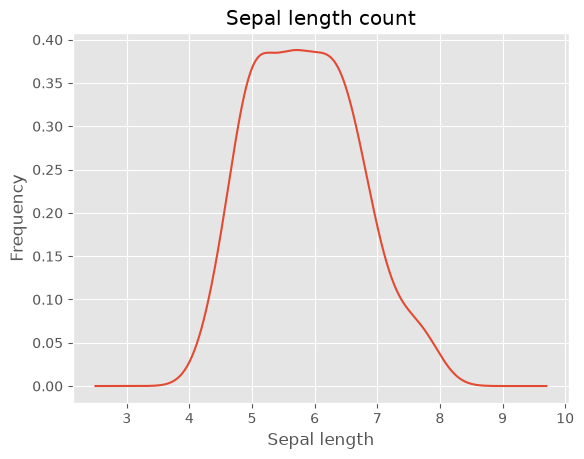

In [79]:
ax = df['sepal_length'].plot(kind = 'kde',
                title = 'Sepal length count')
ax.set_xlabel('Sepal length')
ax.set_ylabel('Frequency')

# even distribution with mean approximately 5.75cm

Text(0, 0.5, 'Frequency')

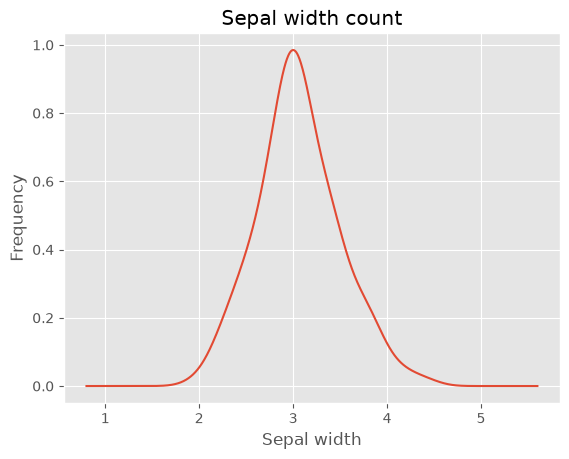

In [80]:
ay = df['sepal_width'].plot(kind = 'kde',
                title = 'Sepal width count')
ay.set_xlabel('Sepal width')
ay.set_ylabel('Frequency')

# even distribution with mean approximately 3cm

Text(0, 0.5, 'Frequency')

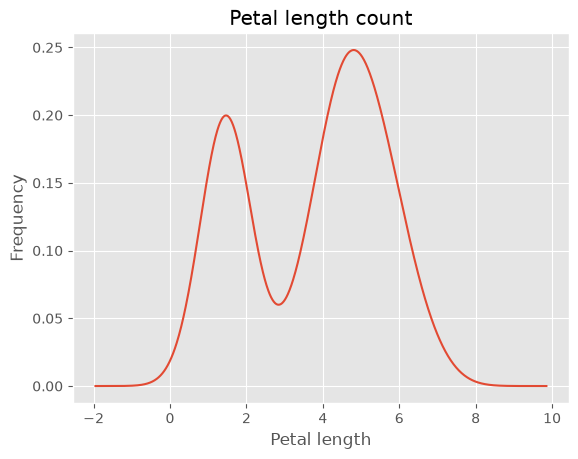

In [81]:
bx = df['petal_length'].plot(kind = 'kde',
                title = 'Petal length count')
bx.set_xlabel('Petal length')
bx.set_ylabel('Frequency')

# quite strange distribution with 2 maximums and 1 dip in between at around

Text(0, 0.5, 'Frequency')

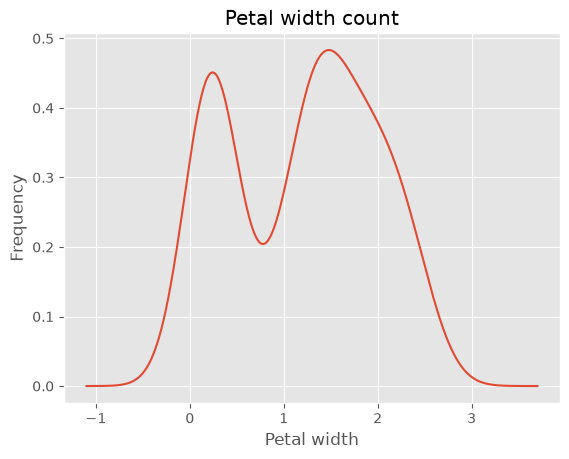

In [82]:
by = df['petal_width'].plot(kind = 'kde',
                title = 'Petal width count')
by.set_xlabel('Petal width')
by.set_ylabel('Frequency')

# quite similar distribution shape to petal length, so the distribution is probably specific to petal or sepal

Text(0, 0.5, 'Counts')

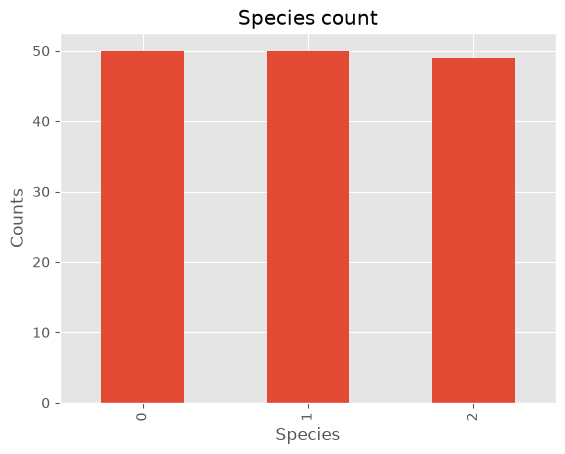

In [83]:
sp = df['species'].value_counts().head(10).plot(kind = 'bar', title = 'Species count')

sp.set_xlabel('Species')
sp.set_ylabel('Counts')

# The amount of each species is very close to each other. I assume at first it was 50-50-50 but then I removed a duplicate so it is 50-50-49

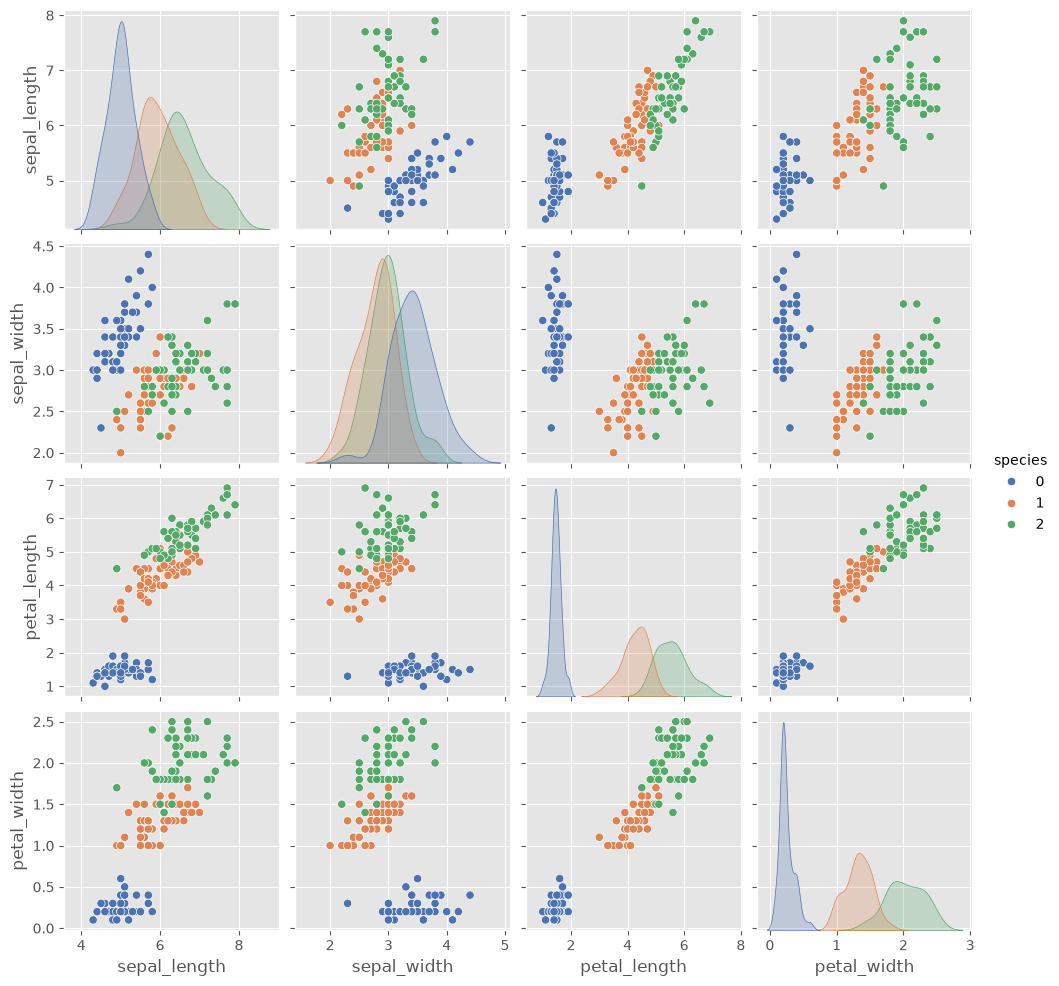

In [84]:
sns.pairplot(df,
             vars = ['sepal_length','sepal_width','petal_length','petal_width'],
             hue = 'species',
             palette='deep')
plt.show()

# We can see the species 0 is quite different from the other two. 1 and 2 have traits closer to each other but there are still some distinction.
# Compare the sepal_width vs sepal_length graph with the one given by sklearn. We can detect the species as follow:
# 0 - setosa, 1 - versicolor, 2 - virginica

# Modelling:

## Classification models

### Tensorflow

In [85]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.model_selection import train_test_split

In [86]:
# Create training/test sets

X = df.drop(columns='species')
y = df['species']

# Get 60% of the dataset as the training set. Put the remaining 40% in temporary variables: x_ and y_.
X_train, X_, y_train, y_ = train_test_split(X, y, test_size=0.40, random_state=1)

# Split the 40% subset above into two: one half for cross validation and the other for the test set
X_cv, X_test, y_cv, y_test = train_test_split(X_, y_, test_size=0.50, random_state=1)

# Delete temporary variables
del X_, y_

In [87]:
# Create model
model_tf = Sequential(
    [
        Dense(2, activation = 'relu',   name = "L1"), # 2 lines
        Dense(3, activation = 'linear', name = "L2")  # 3 values
    ]
)

In [88]:
# Train model with training set

model_tf.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer=tf.keras.optimizers.Adam(0.01),
)

model_tf.fit(
    X_train,y_train,
    epochs=1000
)

#Run until the loss does not drop anymore, about 0.0700

Epoch 1/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 3.4297  
Epoch 2/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 2.7627 
Epoch 3/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 2.2562 
Epoch 4/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.8614 
Epoch 5/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.6195 
Epoch 6/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.4440 
Epoch 7/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.3284 
Epoch 8/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 1.2553
Epoch 9/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.2043 
Epoch 10/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.1750 
Epoch 11/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.1492 
Epoch 12/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 1.1327 
Epoch 13/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.1221 
Epoch 14/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.1189 
Epoch 15/1000
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.1167 
Epo

In [89]:
# Accuracy check on CV 
from sklearn.metrics import accuracy_score
y_pred_probs_cv_tf = model_tf.predict(X_cv)
y_pred_cv_tf = np.argmax(y_pred_probs_cv_tf, axis=1) # get the highest value
accuracy_cv_tf = accuracy_score(y_cv, y_pred_cv_tf)
print(f"CV accuracy for tensorflow model: {accuracy_cv_tf:.3f}")

# this model does very well on Iris

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
CV accuracy for tensorflow model: 1.000


### Pytorch

In [90]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

In [91]:
# Convert data to float32 tensors
Xtrain = torch.tensor(X_train.to_numpy(), dtype=torch.float32)
ytrain = torch.tensor(y_train.to_numpy(), dtype=torch.long)
Xcv = torch.tensor(X_cv.to_numpy(), dtype=torch.float32)
ycv = torch.tensor(y_cv.to_numpy(), dtype=torch.long)
Xtest = torch.tensor(X_test.to_numpy(), dtype=torch.float32)
ytest = torch.tensor(y_test.to_numpy(), dtype=torch.long)

In [92]:
# Check if I am using my GPU

device = "cuda" if torch.cuda.is_available() else "cpu"
print(torch.cuda.is_available())

True


In [93]:
n = Xtrain.shape[1] #number of input features

# Create same model as Tensorflow above
model_pt = nn.Sequential(
    nn.Linear(n,2), nn.ReLU(),
    nn.Linear(2,3)
)

In [94]:
loss_func = nn.CrossEntropyLoss() #loss function
optimizer = torch.optim.Adam(model_pt.parameters(), lr=0.01)
# Mini-batches of 10, reshuffled every epoch
train_loader = DataLoader(TensorDataset(Xtrain, ytrain), batch_size=10, shuffle=True)

for epoch in range(1000):
    total = 0
    for x_b, y_b in train_loader:
        optimizer.zero_grad()
        loss = loss_func(model_pt(x_b), y_b)
        loss.backward()
        optimizer.step()
        total += loss.item() 
    print("Epoch:", epoch + 1, "Avg loss:", total / len(train_loader)) #print average loss per epoch



Epoch: 1 Avg loss: 1.9071728123558893
Epoch: 2 Avg loss: 1.2917782598071628
Epoch: 3 Avg loss: 1.1157670153511896
Epoch: 4 Avg loss: 1.109051850106981
Epoch: 5 Avg loss: 1.1057837009429932
Epoch: 6 Avg loss: 1.1035880910025702
Epoch: 7 Avg loss: 1.102237966325548
Epoch: 8 Avg loss: 1.101240462727017
Epoch: 9 Avg loss: 1.100219554371304
Epoch: 10 Avg loss: 1.0996413495805528
Epoch: 11 Avg loss: 1.0994801653756037
Epoch: 12 Avg loss: 1.0992641713884141
Epoch: 13 Avg loss: 1.0996940798229642
Epoch: 14 Avg loss: 1.099288198682997
Epoch: 15 Avg loss: 1.0991751617855496
Epoch: 16 Avg loss: 1.0994082689285278
Epoch: 17 Avg loss: 1.0991142061021593
Epoch: 18 Avg loss: 1.099133054415385
Epoch: 19 Avg loss: 1.0989395644929674
Epoch: 20 Avg loss: 1.0988439851337009
Epoch: 21 Avg loss: 1.0988053878148396
Epoch: 22 Avg loss: 1.0987352265252008
Epoch: 23 Avg loss: 1.09908303949568
Epoch: 24 Avg loss: 1.0988584227032132
Epoch: 25 Avg loss: 1.0990100171830919
Epoch: 26 Avg loss: 1.098878092235989
Epoc

In [95]:
# Accuracy check on CV
model_pt.eval()
with torch.no_grad(): # to save memory, and have faster forward pass (practice for bigger dataset in the future)
    logits_cv_pt = model_pt(Xcv) #raw scores, not probabilities
y_pred_cv_pt = logits_cv_pt.argmax(dim=1).numpy() #highest score = predicted class
accuracy_cv_pt = accuracy_score(y_cv, y_pred_cv_pt)
print(f"CV accuracy for pytorch model: {accuracy_cv_pt:.3f}")

# this model also works well on Iris

CV accuracy for pytorch model: 0.300


### Test models

In [96]:
# Accuracy check on test set for tf model
y_pred_probs_test_tf = model_tf.predict(X_test)
y_pred_test_tf = np.argmax(y_pred_probs_test_tf, axis=1) # get the highest value
accuracy_test_tf = accuracy_score(y_test, y_pred_test_tf)
print(f"Test accuracy for tensorflow model: {accuracy_test_tf:.3f}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step
Test accuracy for tensorflow model: 1.000


In [97]:
# Accuracy check on test set for pt model
model_pt.eval()
with torch.no_grad():
    logits_test_pt = model_pt(Xtest) 
y_pred_test_pt = logits_test_pt.argmax(dim=1).numpy()
accuracy_test_pt = accuracy_score(y_test, y_pred_test_pt)
print(f"Test accuracy for pytorch model: {accuracy_test_pt:.3f}")

Test accuracy for pytorch model: 0.367


Both have perfect accuracy on CV and test sets. This shows that Iris from sklearn is a very clean dataset with predictable patterns.

## Clustering

I want to see if the patterns are clear enough for clustering to work as well as classification

In [98]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

cluster   0   1   2
species            
0         0   0  50
1        48   2   0
2        13  36   0
Accuracy: 0.8993288590604027


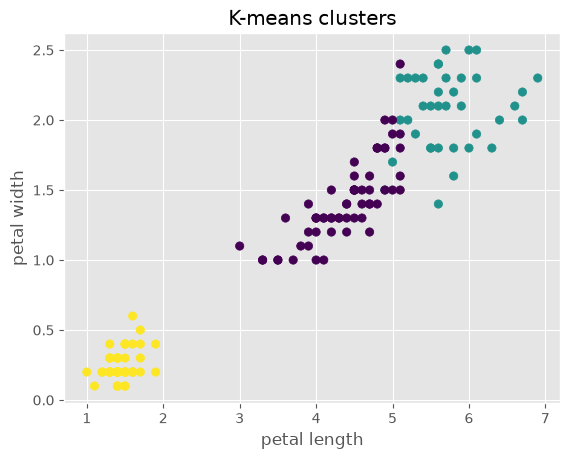

In [99]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=0)
labels = kmeans.fit_predict(X)

# Cluster numbers are arbitrary, so compare with a crosstab => shows the frequency of points of true species y having a certain labels
print(pd.crosstab(y, labels, rownames=['species'], colnames=['cluster']))


# Map each cluster to the species it mostly contains, then compute accuracy
mapping = pd.crosstab(labels, y).idxmax(axis=1) # create a pd series that acts as a dictionary
y_pred = pd.Series(labels).map(mapping) # act the same as a loop using to dictionary to map
print('Accuracy:', accuracy_score(y, y_pred))

# Plot the clusters on the two most informative features
plt.scatter(X['petal_length'], X['petal_width'], c=labels)
plt.xlabel('petal length'); plt.ylabel('petal width'); plt.title('K-means clusters')
plt.show()

We can see that for species 0 the clustering algorithm gets 50/50, but for the other two there are some misclassifications. However, having a 89-90% accuracy is still really decent. 